<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1) Import the libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
import warnings
warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

# **2)Load the dataset**

In [3]:
df = pd.read_csv("/content/dataset_diabetes_exp_9.csv")
print(df.shape)
print(df.head())
print(df["Outcome"].value_counts())

(768, 9)
   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]
Outcome
0    500
1    268
Name: count, dtype: int64


In [4]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


# **3)Train Test Split**

In [5]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)   # learn medians from train only
X_test = imputer.transform(X_test)

# **4) Build the 3 models**

In [6]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(),
                                 n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

# **5) Train and evaluate all the models**

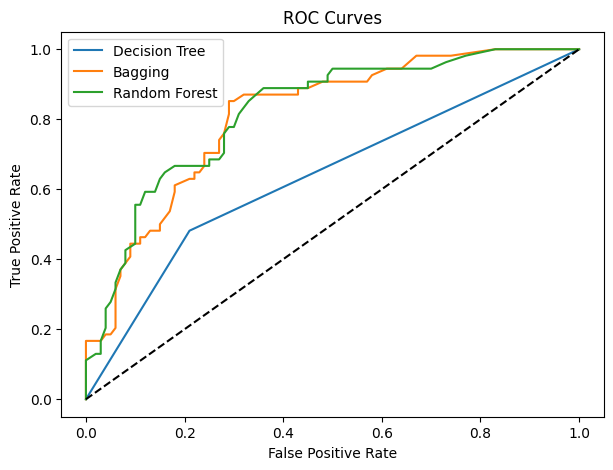

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV Accuracy
0,Decision Tree,0.682,0.553,0.481,0.515,0.636,0.692
1,Bagging,0.727,0.636,0.519,0.571,0.810,0.744
2,Random Forest,0.766,0.696,0.593,0.640,0.821,0.774


In [7]:
results = []
plt.figure(figsize=(7, 5))

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    cv = cross_val_score(model, X_train, y_train, cv=5).mean()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "CV Accuracy": cv,
    })

    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

results_df = pd.DataFrame(results).round(3)
results_df

# **6) Compare Accuracy in bar chart**

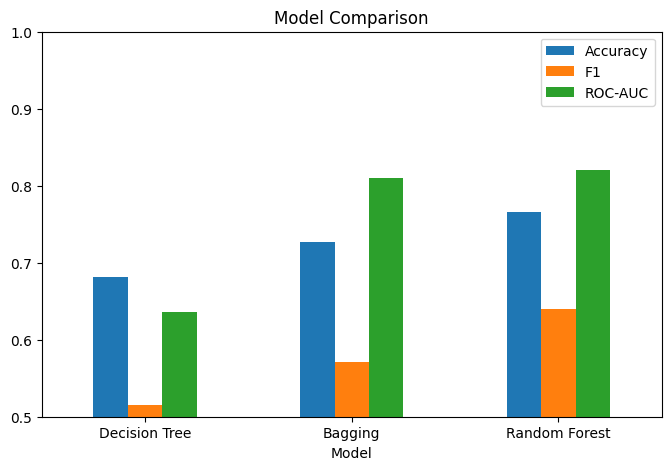

In [8]:
results_df.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model Comparison")
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.show()

# **7) Comfusion Matrices**

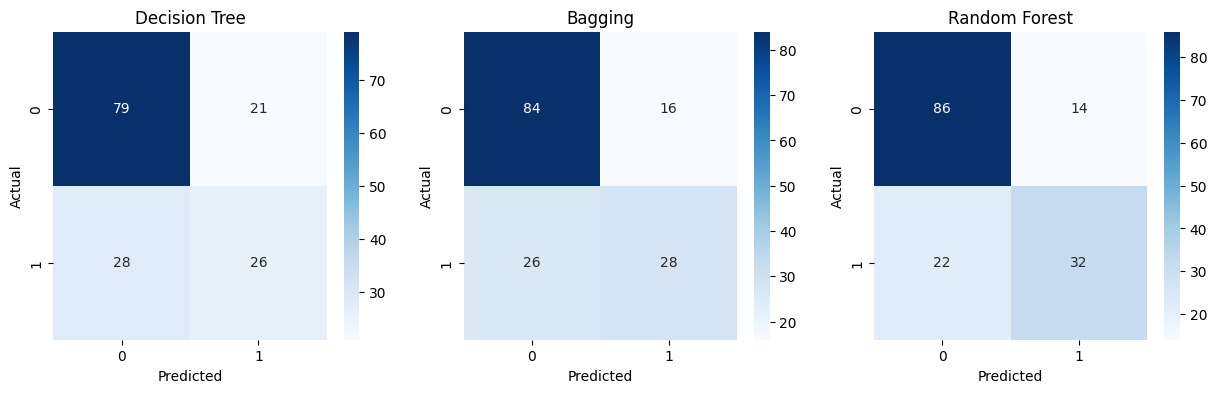

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.show()

# **8) Random Forest**

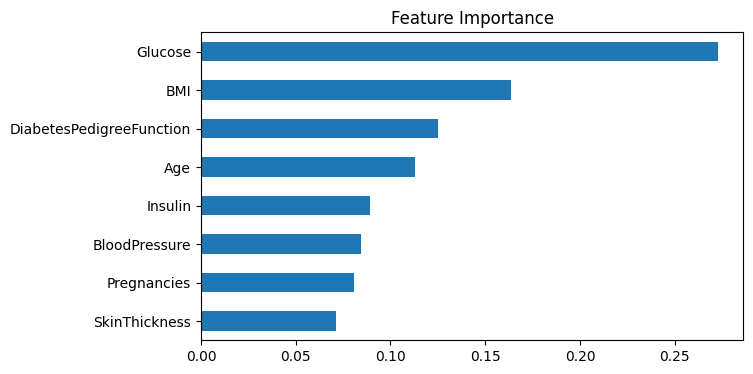

In [10]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
imp.sort_values().plot(kind="barh", figsize=(7, 4), title="Feature Importance")
plt.show()